In [1]:
!pip install GEOparse statsmodels

In [2]:
import pandas as pd, numpy as np, GEOparse

data = pd.read_csv("tnbc_data.csv", index_col=0)
y = data["label"]
X = data.drop(columns="label")
print(X.values.max())   # about 15 is fine. If above 100, run: X = np.log2(X + 1)

gse = GEOparse.get_GEO("GSE76275", destdir="./")
gpl = gse.gpls["GPL570"].table
m = gpl[["ID", "Gene Symbol"]].dropna()
m = m[~m["Gene Symbol"].str.contains("///")]
mapping = dict(zip(m["ID"], m["Gene Symbol"]))

X = X.T
X["gene"] = X.index.map(mapping)
X = X.dropna(subset=["gene"]).groupby("gene").mean().T
print(X.shape)   # about (265, 20000)

21-Nov-2026 15:09:03 DEBUG utils - Directory ./ already exists. Skipping.
DEBUG:GEOparse:Directory ./ already exists. Skipping.
21-Nov-2026 15:09:03 INFO GEOparse - Downloading ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE76nnn/GSE76275/soft/GSE76275_family.soft.gz to ./GSE76275_family.soft.gz
INFO:GEOparse:Downloading ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE76nnn/GSE76275/soft/GSE76275_family.soft.gz to ./GSE76275_family.soft.gz


15.61709607


100%|██████████| 129M/129M [00:02<00:00, 65.9MB/s]
21-Nov-2026 15:09:06 DEBUG downloader - Size validation passed
DEBUG:GEOparse:Size validation passed
21-Nov-2026 15:09:06 DEBUG downloader - Moving /tmp/tmpbkncjfu8 to /content/GSE76275_family.soft.gz
DEBUG:GEOparse:Moving /tmp/tmpbkncjfu8 to /content/GSE76275_family.soft.gz
21-Nov-2026 15:09:06 DEBUG downloader - Successfully downloaded ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE76nnn/GSE76275/soft/GSE76275_family.soft.gz
DEBUG:GEOparse:Successfully downloaded ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE76nnn/GSE76275/soft/GSE76275_family.soft.gz
21-Nov-2026 15:09:06 INFO GEOparse - Parsing ./GSE76275_family.soft.gz: 
INFO:GEOparse:Parsing ./GSE76275_family.soft.gz: 
21-Nov-2026 15:09:06 DEBUG GEOparse - DATABASE: GeoMiame
DEBUG:GEOparse:DATABASE: GeoMiame
21-Nov-2026 15:09:06 DEBUG GEOparse - SERIES: GSE76275
DEBUG:GEOparse:SERIES: GSE76275
21-Nov-2026 15:09:06 DEBUG GEOparse - PLATFORM: GPL570
DEBUG:GEOparse:PLATFORM: GPL570
/usr/local/l

(265, 21655)


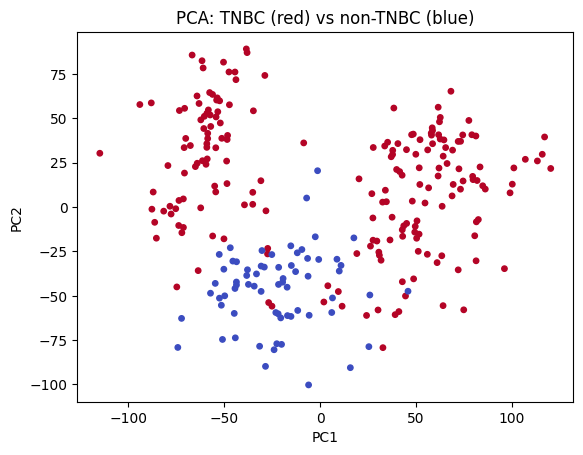

In [3]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pc = PCA(n_components=2).fit_transform((X - X.mean()) / X.std())
plt.scatter(pc[:, 0], pc[:, 1], c=y, cmap="coolwarm", s=15)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("PCA: TNBC (red) vs non-TNBC (blue)")
plt.savefig("pca.png", dpi=200); plt.show()

In [4]:
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

t, p = ttest_ind(X[y == 1], X[y == 0], equal_var=False)
res = pd.DataFrame({"logFC": X[y == 1].mean() - X[y == 0].mean(), "p": p}, index=X.columns)
res["FDR"] = multipletests(res["p"], method="fdr_bh")[1]
res = res.sort_values("p")
print((res["FDR"] < 0.05).sum(), "significant genes")

13496 significant genes


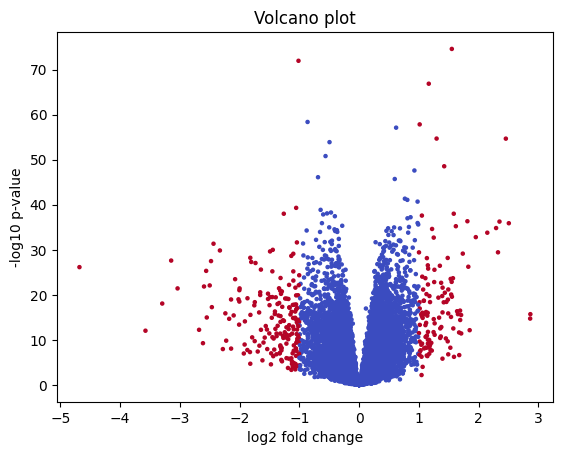

In [5]:
sig = (res["FDR"] < 0.05) & (res["logFC"].abs() > 1)
plt.scatter(res["logFC"], -np.log10(res["p"]), c=sig, cmap="coolwarm", s=5)
plt.xlabel("log2 fold change"); plt.ylabel("-log10 p-value"); plt.title("Volcano plot")
plt.savefig("volcano.png", dpi=200); plt.show()

In [6]:
top = res.head(500)
top.to_csv("top500_DEGs.csv")
X[top.index].assign(label=y).to_csv("tnbc_top500.csv")
print(top.head(10))

                 logFC             p           FDR
gene                                              
FZD9          1.551756  2.537657e-75  5.495296e-71
COL18A1-AS1  -1.014544  1.090431e-72  1.180664e-68
SKA1          1.165957  1.338017e-67  9.658251e-64
AX746627     -0.862589  4.163379e-59  2.253949e-55
KCNQ4         1.013761  1.446287e-58  6.263868e-55
LINC00669     0.619512  7.670066e-58  2.768255e-54
ORC1          1.296832  2.035670e-55  5.688152e-52
EN1           2.455942  2.101372e-55  5.688152e-52
RP11-55K13.1 -0.495239  1.261101e-54  3.034348e-51
FRMD7        -0.561948  1.562639e-51  3.383895e-48
